## CSE428 - Image Processing Lab Project

## Importing Libraries

In [ ]:
# Download from Drive
import gdown
import os

# Compressed [tar.gz] file extraction
import tarfile

# Essentials
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import skimage as ski
from skimage import io, color, exposure
import random
import numpy as np
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms

import albumentations as A
from torch.utils.data import Dataset
from skimage import io
import os
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import precision_recall_fscore_support, accuracy_score




## All Helper Functions


In [ ]:
def get_image_and_mask(index, fix_mask_bool = True):
    image_path = os.path.join(image_dir, image_files[index])
    mask_path = os.path.join(mask_dir, mask_files[index])

    image = io.imread(image_path)
    mask = io.imread(mask_path)

    if fix_mask_bool:
      mask = fix_mask(mask)

    return image, mask

def fix_mask(mask):
    # 3 == border, 2 == background, 1 == pet
    mask[mask == 1] = 1
    mask[mask == 2] = 0
    mask[mask == 3] = 1
    return mask


def masked_image(image, mask):
    overlay = image.copy()
    green = np.array([120, 255, 120])

    overlay[mask == 1] = (
        0.5 * overlay[mask == 1] + 0.2 * green
    ).astype(np.uint8)

    return overlay

def get_mask_file(image_file):
    return image_file.rsplit(".", 1)[0] + ".png"

## 1. Dataset Exploration

### Loading Dataset

In [ ]:
# Download images
images_id = '1kC76idpPPsgblFuHuTJ_IS_Z03SkrZp2'
images_output = 'images.tar.gz'
gdown.download(f'https://drive.google.com/uc?id={images_id}', images_output, quiet=False)

# Download annotations
annotations_id = '1pO-01_btc00nJcXm2_ZI-s9rQwrNke1O'
annotations_output = 'annotations.tar.gz'
gdown.download(f'https://drive.google.com/uc?id={annotations_id}', annotations_output, quiet=False)

print("\n\nDownloads complete.")

Downloading...
From (original): https://drive.google.com/uc?id=1kC76idpPPsgblFuHuTJ_IS_Z03SkrZp2
From (redirected): https://drive.google.com/uc?id=1kC76idpPPsgblFuHuTJ_IS_Z03SkrZp2&confirm=t&uuid=6046b19d-72a8-4622-bf54-47c0ef60a1fa
To: f:\cse428\images.tar.gz


KeyboardInterrupt: 

In [ ]:
# Extract images
with tarfile.open('images.tar.gz', 'r:gz') as tar:
    tar.extractall('images', filter='data')
print('Images extracted.')

# Extract annotations
with tarfile.open('annotations.tar.gz', 'r:gz') as tar:
    tar.extractall('annotations', filter='data')
print('Annotations extracted.')

Images extracted.
Annotations extracted.


### Understanding Data



In [ ]:
# List contents of extracted directories to verify
print("First 10 Contents of 'images' directory:")
!ls -F images/images | head -10
print()


print("Contents  of 'annotations' directory:")
!ls -F annotations/annotations | head -10

First 10 Contents of 'images' directory:

Contents  of 'annotations' directory:


'ls' is not recognized as an internal or external command,
operable program or batch file.
'ls' is not recognized as an internal or external command,
operable program or batch file.


In [ ]:
print("First 10 trimaps:")
!ls -F annotations/annotations/trimaps | head -10

First 10 trimaps:


'ls' is not recognized as an internal or external command,
operable program or batch file.


In [ ]:
image_dir = "images/images"
mask_dir = "annotations/annotations/trimaps"
list_file = "annotations/annotations/list.txt"

In [ ]:
image_files = [f for f in os.listdir(image_dir) if f.endswith('.jpg')]
mask_files = [f for f in os.listdir(mask_dir) if f.endswith('.png') and not f.startswith('._')]

# Sort them to ensure corresponding images and masks match if they follow a naming convention
image_files.sort()
mask_files.sort()

In [ ]:
# Each image ends with .jpg
print("Number of images:", len([f for f in os.listdir(image_dir) if f.endswith(".jpg")]))

# Each mark ends with .png
# if the file starts with ._ --> It is an AppleDouble file (Metadata created by MacOS)
print("Number of masks:", len([f for f in os.listdir(mask_dir) if f.endswith(".png") and not f.startswith("._")]))

Number of images: 7390
Number of masks: 7390


In [ ]:
with open(list_file, "r") as f:
    lines = f.readlines()

print("Starting of the List File:\n\n")
lineNo = 1

for line in lines[:8]:
    print(f"Line No: {lineNo}: ", line.strip())
    print()
    lineNo += 1

Starting of the List File:


Line No: 1:  #Image CLASS-ID SPECIES BREED ID

Line No: 2:  #ID: 1:37 Class ids

Line No: 3:  #SPECIES: 1:Cat 2:Dog

Line No: 4:  #BREED ID: 1-25:Cat 1:12:Dog

Line No: 5:  #All images with 1st letter as captial are cat images

Line No: 6:  #images with small first letter are dog images

Line No: 7:  Abyssinian_100 1 1 1

Line No: 8:  Abyssinian_101 1 1 1



In [ ]:
# Verify dataset classes

class_ids = set()
species_ids = set()
cat_breeds = set()
dog_breeds = set()

with open(list_file, "r") as f:
    for line in f:
        line = line.strip()

        # Skip comments and empty lines
        if not line or line.startswith("#"):
            continue

        parts = line.split()

        if len(parts) >= 4:
            class_id = int(parts[1])
            species_id = int(parts[2])
            breed_id = int(parts[3])

            class_ids.add(class_id)
            species_ids.add(species_id)

            if species_id == 1:
                cat_breeds.add(breed_id)
            elif species_id == 2:
                dog_breeds.add(breed_id)

print("Number of classes:", len(class_ids))
print("Class IDs:", sorted(class_ids))

print("\nNumber of species:", len(species_ids))
print("Species IDs:", sorted(species_ids))

print("\nNumber of cat breeds:", len(cat_breeds))
print("Number of dog breeds:", len(dog_breeds))

Number of classes: 37
Class IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37]

Number of species: 2
Species IDs: [1, 2]

Number of cat breeds: 12
Number of dog breeds: 25


In [ ]:
# Create a mapping from image name to class ID for the Dataset class
labels = {}
with open(list_file, "r") as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        parts = line.split()
        if len(parts) >= 2:
            image_name = parts[0]
            class_id = int(parts[1])
            labels[image_name] = class_id

CLASS_NAMES      = [None] * 37
LABEL_TO_SPECIES = [None] * 37
SPECIES_NAMES    = ["Cat", "Dog"]

for image_name, class_id in labels.items():
    label = class_id - 1
    breed = image_name.rsplit("_", 1)[0]
    CLASS_NAMES[label]      = breed.replace("_", " ").title()
    LABEL_TO_SPECIES[label] = 0 if breed[0].isupper() else 1    # capital = cat, per list.txt

before = len(image_files)

image_files = [f for f in image_files if f.rsplit(".", 1)[0] in labels]
mask_files  = [get_mask_file(f) for f in image_files]   # rebuild so index i still pairs up

print(f"Dropped {before - len(image_files)} images with no entry in list.txt "
      f"({before} -> {len(image_files)})")

print(f"Mapping created for {len(labels)} images.")

Dropped 41 images with no entry in list.txt (7390 -> 7349)
Mapping created for 7349 images.


---

### Dataset Explanation


The dataset contains pet images and their corresponding annotations.

- `images/images/` — Original pet images used as model input. **7,390 images**.
- `annotations/annotations/trimaps/` — Pixel-level masks used as segmentation ground truth. **7,390 masks**.
- `annotations/annotations/list.txt` — Contains the class, species, and breed information used for classification.
  - **37 classes** in total.
  - **2 species:** Cat and Dog.
  - **25 cat breeds** and **12 dog breeds**.


---



### Inspect Images and Masks

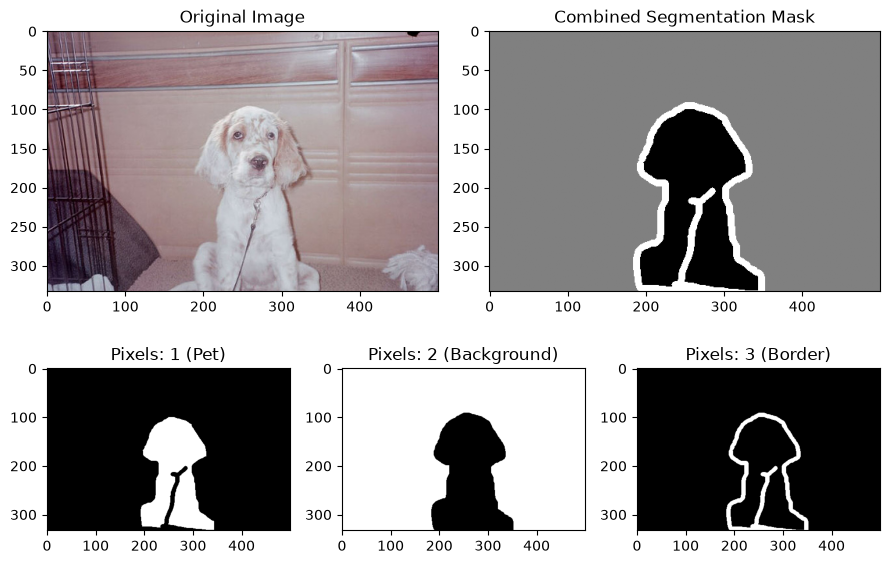

In [ ]:
# Select a random index
random_index = random.randint(0, len(image_files) - 1)

# Read the image and mask using skimage
image, mask = get_image_and_mask(random_index, False) # Saihan, Ignore this bool:false for now

# Set up a grid layout: 2 rows, 6 columns total
fig = plt.figure(figsize=(9, 6))
gs = gridspec.GridSpec(2, 6, figure=fig)

# --- Top Row ---
# 1. Original Image
ax1 = fig.add_subplot(gs[0, 0:3])
ax1.imshow(image)
ax1.set_title('Original Image')

# 2. Combined Segmentation Mask
ax2 = fig.add_subplot(gs[0, 3:6])
ax2.imshow(mask, cmap='gray')
ax2.set_title('Combined Segmentation Mask')


# --- Bottom Row ---
# Mask for pixels equal to 1
ax3 = fig.add_subplot(gs[1, 0:2])
ax3.imshow(mask == 1, cmap='gray')
ax3.set_title('Pixels: 1 (Pet)')

# Mask for pixels equal to 2
ax4 = fig.add_subplot(gs[1, 2:4])
ax4.imshow(mask == 2, cmap='gray')
ax4.set_title('Pixels: 2 (Background)')

# Mask for pixels equal to 3
ax5 = fig.add_subplot(gs[1, 4:6])
ax5.imshow(mask == 3, cmap='gray')
ax5.set_title('Pixels: 3 (Border)')

plt.tight_layout()
plt.show()

### Fix Unclassified / Boundary Pixels

In [ ]:
# The mask values in this dataset are: 1 for pet, 2 for background, 3 for border.

'''The helper function which deals with the masks is in an upper cell above (All Helper Function)

The Fixer:

Background == 0
Pet and Border == 1
'''

'The helper function which deals with the masks is in an upper cell above (All Helper Function)\n\nThe Fixer:\n\nBackground == 0\nPet and Border == 1\n'

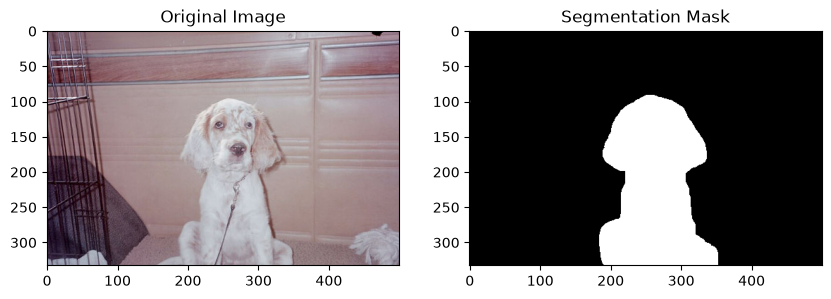

In [ ]:
image, mask = get_image_and_mask(random_index)

# Display the image and mask (Fixed Version lol)
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title('Original Image')
# plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap='gray', vmin = 0, vmax= 1)
plt.title('Segmentation Mask')
# plt.axis('off')

plt.show()

### Visualize 9 Random Samples

In [ ]:
randomSamples = np.random.choice(len(image_files), 9, replace=False)


'''
Trust me, this is random
'''
randomSamples = [1598, 4643,  935, 6092, 5870, 4766,  262, 5188, 5912]

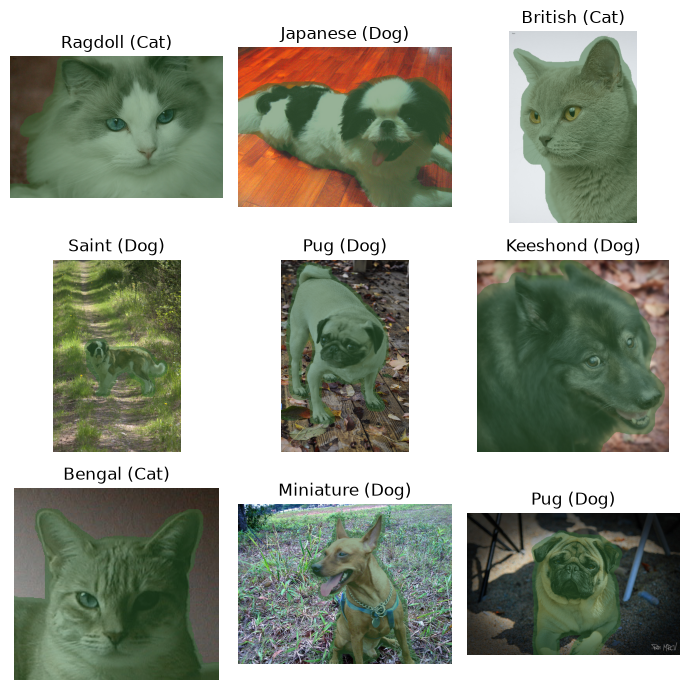

In [ ]:
# Code to visualize random samples
fig, axes = plt.subplots(3, 3, figsize=(7, 7))

for ax, index in zip(axes.flat, randomSamples):
    image, mask = get_image_and_mask(index)
    result = masked_image(image, mask)

    variant = image_files[index].split("_")[0]
    species = "Cat" if variant[0].isupper() else "Dog"

    ax.imshow(result)
    ax.set_title(f"{variant.title()} ({species})")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 2. Data Preprocessing

### Define Preprocessing Pipeline

In [ ]:
X = 128
IMAGE_SIZE = (X, X)

# Image preprocessing
image_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406], # ImageNet Mean and STD values
        std=[0.229, 0.224, 0.225]
    )
])

"""masks shouldn't be normalized like images and need nearest-neighbor resizing"""

# Mask preprocessing
def preprocess_mask(mask):
    # Convert trimap:
    # 1 = foreground
    # 2 = background
    # 3 = foreground (boundary)
    mask = (mask == 1) | (mask == 3)

    mask = torch.from_numpy(mask.astype("float32"))
    mask = mask.unsqueeze(0)

    mask = torch.nn.functional.interpolate(
        mask.unsqueeze(0),
        size=IMAGE_SIZE,
        mode="nearest"
    ).squeeze(0)

    return mask

from PIL import Image

RESIZED_CACHE = {}

def load_resized(image_file):
    if image_file in RESIZED_CACHE:
        return RESIZED_CACHE[image_file]

    image_name = image_file.rsplit(".", 1)[0]
    image = Image.open(os.path.join(image_dir, image_file)).convert("RGB")
    image = image.resize(IMAGE_SIZE, Image.BILINEAR)
    mask  = Image.open(os.path.join(mask_dir, image_name + ".png"))
    mask  = mask.resize(IMAGE_SIZE, Image.NEAREST)     # NEAREST keeps the labels 1/2/3 intact

    pair = (np.asarray(image, dtype=np.uint8), np.asarray(mask, dtype=np.uint8))
    RESIZED_CACHE[image_file] = pair
    return pair


for f in image_files:        # fill it once, ~1-2 minutes
    load_resized(f)
print(f"Cached {len(RESIZED_CACHE)} images in RAM")

Cached 7349 images in RAM


### Train / Validation / Test Split

In [ ]:
# 70-15-15 Split
train_files, temp_files = train_test_split(
    image_files,
    test_size=0.30,
    random_state=404
)

val_files, test_files = train_test_split(
    temp_files,
    test_size=0.50,
    random_state=404
)

print("Training:", len(train_files))
print("Validation:", len(val_files))
print("Testing:", len(test_files))

Training: 5144
Validation: 1102
Testing: 1103


### Data Augmentation

In [ ]:
train_augmentation = A.Compose([
    A.HorizontalFlip(p=0.5),

    A.ShiftScaleRotate(
        shift_limit=0.05,
        scale_limit=0.10,
        rotate_limit=10,
        p=0.5
    ),

    A.RandomBrightnessContrast(
        brightness_limit=0.15,
        contrast_limit=0.15,
        p=0.3
    )
])

f:\cse428\.venv\Lib\site-packages\albumentations\core\validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


### Pet Dataset Objectified

In [ ]:
class PetDataset(Dataset):

    def __init__(
        self,
        image_files,
        image_transform=None,
        augmentation=None
    ):
        self.image_files = image_files
        self.image_transform = image_transform
        self.augmentation = augmentation

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, index):
        image_file = self.image_files[index]
        image_name = image_file.rsplit(".", 1)[0]

        image, mask = load_resized(image_file)     # already 128x128 uint8, no decoding
        image, mask = image.copy(), mask.copy()    # augmentation writes in place

        if self.augmentation:
            augmented = self.augmentation(image=image, mask=mask)
            image, mask = augmented["image"], augmented["mask"]

        if self.image_transform:
            image = self.image_transform(image)

        mask = preprocess_mask(mask)
        label = labels[image_name] - 1
        return image, mask, label

Image shape: torch.Size([3, 128, 128])
Mask shape: torch.Size([1, 128, 128])
Label: 30


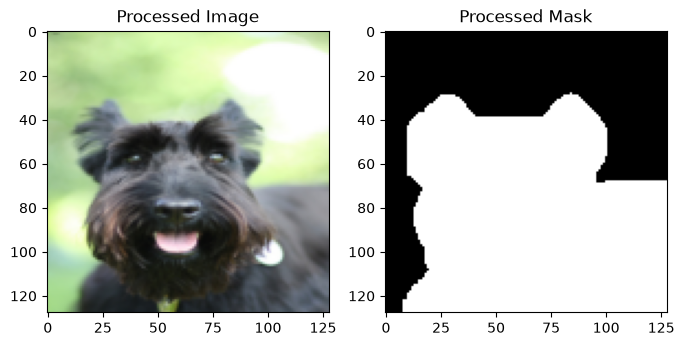

In [ ]:
# Testing if PetDataset works
temp_ds = PetDataset(train_files, image_transform=image_transform, augmentation=train_augmentation)
img, msk, lbl = temp_ds[0]

print(f"Image shape: {img.shape}")
print(f"Mask shape: {msk.shape}")
print(f"Label: {lbl}")

# Visualize the processed sample
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
# Unnormalize image for visualization
plt.imshow(img.permute(1, 2, 0) * torch.tensor([0.229, 0.224, 0.225]) + torch.tensor([0.485, 0.456, 0.406]))
plt.title("Processed Image")
plt.subplot(1, 2, 2)
plt.imshow(msk.squeeze(), cmap='gray')
plt.title("Processed Mask")
plt.show()

### Prepare DataLoaders



In [ ]:
# PetDataset will take over the world someday, maybe.

train_dataset = PetDataset(
    train_files,
    image_transform=image_transform,
    augmentation=train_augmentation
)

val_dataset = PetDataset(
    val_files,
    image_transform=image_transform
)

test_dataset = PetDataset(
    test_files,
    image_transform=image_transform
)

In [ ]:
# Dataloaders

BATCH_SIZE = 32
'''
Does batch_size matter here??
Yes, more is better but slower
'''

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

## 3. Base U-Net

### Define U-Net Architecture

In [ ]:
# Code to define U-Net architecture
CFG = {
    "n_classes":37,
    "image_size":128,
    "base_ch": 32,
    "bce_weight": 0.5,
    "lambda_cls": 0.5,
}

class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding='same', bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding='same', bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.double_conv(x)


class UNetEncoder(nn.Module):

    def __init__(self, in_channels=3, first_out_channel=32):
        super().__init__()
        c = first_out_channel

        self.enc1 = ConvBlock(in_channels, c)        #   3 ->  32
        self.enc2 = ConvBlock(c, c * 2)              #  32 ->  64
        self.enc3 = ConvBlock(c * 2, c * 4)          #  64 -> 128
        self.enc4 = ConvBlock(c * 4, c * 8)          # 128 -> 256

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        x1 = self.enc1(x)                   #  32 channels x 128
        x2 = self.enc2(self.pool(x1))        #  64 channels x  64
        x3 = self.enc3(self.pool(x2))        # 128 channels x  32
        x4 = self.enc4(self.pool(x3))        # 256 channels x  16
        return x1, x2, x3, x4

class UNetBottleneck(nn.Module):


    def __init__(self, in_channels):
        super().__init__()
        self.enc  = ConvBlock(in_channels, in_channels * 2)     # 256 -> 512
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        return self.enc(self.pool(x))        # 512 channels x 8

class DecoderBlock(nn.Module):


    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up   = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        self.conv = ConvBlock(2 * out_channels, out_channels)

    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([skip, x], dim=1)      # skip connection
        return self.conv(x)

class UNetDecoder(nn.Module):
    """Up-sampling path plus the 1x1 conv that turns features into mask logits."""

    def __init__(self, in_channels=512):
        super().__init__()
        self.decode1 = DecoderBlock(in_channels,      in_channels // 2)    # 512 -> 256
        self.decode2 = DecoderBlock(in_channels // 2, in_channels // 4)    # 256 -> 128
        self.decode3 = DecoderBlock(in_channels // 4, in_channels // 8)    # 128 ->  64
        self.decode4 = DecoderBlock(in_channels // 8, in_channels // 16)   #  64 ->  32

        self.final_conv = nn.Conv2d(in_channels // 16, 1, kernel_size=1)

    def forward(self, x5, x4, x3, x2, x1):
        x4 = self.decode1(x5, x4)            # 256 channels x  16
        x3 = self.decode2(x4, x3)            # 128 channels x  32
        x2 = self.decode3(x3, x2)            #  64 channels x  64
        x1 = self.decode4(x2, x1)            #  32 channels x 128
        return self.final_conv(x1)           #   1 channel  x 128


class Classifier(nn.Module):


    def __init__(self, in_channels=512, num_classes=37, hidden=256, p_drop=0.3):
        super().__init__()
        self.conv  = nn.Conv2d(in_channels, in_channels, kernel_size=3,
                               padding='same', bias=False)
        self.bn    = nn.BatchNorm2d(in_channels)

        self.drop1 = nn.Dropout(p_drop)
        self.fc1   = nn.Linear(in_channels * 2, hidden)     # *2 because avg || max
        self.drop2 = nn.Dropout(p_drop)
        self.fc2   = nn.Linear(hidden, num_classes)         # raw logits for CrossEntropyLoss

    def forward(self, x):
        x = F.relu(self.bn(self.conv(x)))                   # one conv to specialise

        avg = F.adaptive_avg_pool2d(x, (1, 1)).flatten(1)   # [B, 512]
        mx  = F.adaptive_max_pool2d(x, (1, 1)).flatten(1)   # [B, 512]
        x = torch.cat([avg, mx], dim=1)                     # [B, 1024]

        x = self.drop1(x)
        x = F.relu(self.fc1(x))
        x = self.drop2(x)
        return self.fc2(x)                                  # [B, 37]


class UNet(nn.Module):


    def __init__(self, in_channels=3, num_classes=CFG["n_classes"],
                 first_out_channel=CFG["base_ch"]):
        super().__init__()
        c = first_out_channel

        self.encoder    = UNetEncoder(in_channels, c)      # ends at  c*8  = 256
        self.bottleneck = UNetBottleneck(c * 8)            # doubles to c*16 = 512
        self.decoder    = UNetDecoder(c * 16)              # 512 back down to c
        self.classifier = Classifier(c * 16, num_classes)  # reads the 512-channel x5

    def forward(self, x):
        x1, x2, x3, x4 = self.encoder(x)                   # down the left side
        x5 = self.bottleneck(x4)                           # bottom of the U

        seg_logits = self.decoder(x5, x4, x3, x2, x1)      # up the right side
        cls_logits = self.classifier(x5)                   # branch off the bottom

        return seg_logits, cls_logits


# shape smoke test
DEVICE = torch.device("cuda")
USE_AMP = (DEVICE.type == "cuda")
scaler  = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)

image_size = CFG["image_size"]
n_classes  = CFG["n_classes"]

model = UNet().to(DEVICE)
fake_images = torch.randn(2, 3, image_size, image_size, device=DEVICE)

with torch.no_grad():                 #skip the gradient bookkeeping
    seg_output, cls_output = model(fake_images)

print("Segmentation output shape:", tuple(seg_output.shape))
print("  we expect               :", (2, 1, image_size, image_size),
      "-> one mask value per pixel, for each of the 2 images")

print("Classification output shape:", tuple(cls_output.shape))
print("  we expect                 :", (2, n_classes),
      "-> one score per breed, for each of the 2 images")

# Count how many numbers the model has to learn.
total_parameters = sum(p.numel() for p in model.parameters())
print("\nTotal parameters:", f"{total_parameters:,}")

del model, fake_images, seg_output, cls_output    # free the GPU memory again


Segmentation output shape: (2, 1, 128, 128)
  we expect               : (2, 1, 128, 128) -> one mask value per pixel, for each of the 2 images
Classification output shape: (2, 37)
  we expect                 : (2, 37) -> one score per breed, for each of the 2 images

Total parameters: 10,395,270


### Add Classification Head

In [ ]:
# Code to add classification head

### Define Joint Loss

In [ ]:
# Code to define joint loss

class DiceLoss(nn.Module):

    def __init__(self, epsilon=1.0):
        super().__init__()
        self.epsilon = epsilon

    def forward(self, predicted_logits, true_masks):

        predicted = torch.sigmoid(predicted_logits)

        # Flatten image, [batch, 1, 128, 128] -> [batch, 16384]
        batch_size = predicted.shape[0]
        predicted = predicted.reshape(batch_size, -1)
        true      = true_masks.reshape(batch_size, -1)

        overlap = (predicted * true).sum(dim=1)                  # the shared area
        total   = predicted.sum(dim=1) + true.sum(dim=1)         # both areas added up

        dice = (2 * overlap + self.epsilon) / (total + self.epsilon)   # 1.0 = perfect

        return 1 - dice.mean()


class JointLoss(nn.Module):


    def __init__(self, bce_weight=CFG["bce_weight"], lambda_cls=CFG["lambda_cls"]):
        super().__init__()
        self.bce_loss  = nn.BCEWithLogitsLoss()     # per-pixel; "WithLogits" = it applies

        self.dice_loss = DiceLoss()                 # overlap, defined above
        self.ce_loss   = nn.CrossEntropyLoss(label_smoothing=0.05)


        self.bce_weight = bce_weight
        self.lambda_cls = lambda_cls

    def forward(self, predicted_masks, true_masks, predicted_labels, true_labels):

        bce  = self.bce_loss(predicted_masks, true_masks)
        dice = self.dice_loss(predicted_masks, true_masks)
        ce   = self.ce_loss(predicted_labels, true_labels)

        # combine
        segmentation_loss = self.bce_weight * bce + (1 - self.bce_weight) * dice
        total_loss        = segmentation_loss + self.lambda_cls * ce

        parts = {
            "loss":      total_loss.item(),
            "seg_loss":  segmentation_loss.item(),
            "bce":       bce.item(),
            "dice_loss": dice.item(),
            "ce":        ce.item(),
        }
        return total_loss, parts




### Metric

In [ ]:
class MetricTracker:


    def __init__(self):
        self.reset()

    def reset(self):
        # --- pixel counts for the segmentation metrics ("pet" is the positive class) ---
        self.true_positives  = 0.0      # pet pixels called pet
        self.false_positives = 0.0      # background pixels called pet
        self.false_negatives = 0.0      # pet pixels called background
        self.true_negatives  = 0.0      # background pixels called background

        # --- Dice is averaged per image, so we keep a running sum and a count ---
        self.dice_sum   = 0.0
        self.n_images   = 0

        # --- breed predictions, stored so sklearn can compute P / R / F1 at the end ---
        self.predicted_breeds = []
        self.actual_breeds    = []

        # --- running totals of the loss pieces, only used for the printout/curves ---
        self.loss_totals = {}
        self.n_batches   = 0

    @torch.no_grad()
    def update(self, mask_logits, true_masks, breed_logits, true_breeds, loss_parts=None):
        """Add one batch to the running totals."""

        predicted_mask = (torch.sigmoid(mask_logits) > 0.5).float()
        actual_mask    = true_masks.float()

        # [batch, 1, 128, 128] -> [batch, 16384]
        batch_size     = predicted_mask.shape[0]
        predicted_mask = predicted_mask.reshape(batch_size, -1)
        actual_mask    = actual_mask.reshape(batch_size, -1)

        tp = (predicted_mask * actual_mask).sum(dim=1)
        fp = (predicted_mask * (1 - actual_mask)).sum(dim=1)
        fn = ((1 - predicted_mask) * actual_mask).sum(dim=1)
        tn = ((1 - predicted_mask) * (1 - actual_mask)).sum(dim=1)

        self.true_positives  += tp.sum().item()
        self.false_positives += fp.sum().item()
        self.false_negatives += fn.sum().item()
        self.true_negatives  += tn.sum().item()

        dice_per_image = (2 * tp + 1e-6) / (2 * tp + fp + fn + 1e-6)
        self.dice_sum += dice_per_image.sum().item()
        self.n_images += batch_size

        self.predicted_breeds.append(breed_logits.argmax(dim=1).cpu())
        self.actual_breeds.append(true_breeds.cpu())

        if loss_parts is not None:
            for name, value in loss_parts.items():
                self.loss_totals[name] = self.loss_totals.get(name, 0.0) + value
            self.n_batches += 1

    def compute(self):
        """Turn the accumulated counts into the final metrics."""
        epsilon = 1e-9                              # avoids dividing by zero

        # --- segmentation ---
        iou_pet = self.true_positives / (
            self.true_positives + self.false_positives + self.false_negatives + epsilon)

        iou_background = self.true_negatives / (
            self.true_negatives + self.false_positives + self.false_negatives + epsilon)

        mean_iou = (iou_pet + iou_background) / 2

        all_pixels = (self.true_positives + self.true_negatives +
                      self.false_positives + self.false_negatives)
        pixel_accuracy = (self.true_positives + self.true_negatives) / (all_pixels + epsilon)

        mean_dice = self.dice_sum / max(self.n_images, 1)

        # --- classification ---
        predicted = torch.cat(self.predicted_breeds).numpy()
        actual    = torch.cat(self.actual_breeds).numpy()

        breed_accuracy = float(accuracy_score(actual, predicted))
        precision, recall, f1, _ = precision_recall_fscore_support(
            actual, predicted, average="macro", zero_division=0)


        species_of = np.asarray(LABEL_TO_SPECIES)          # breed id -> 0 (cat) or 1 (dog)
        species_accuracy = float((species_of[predicted] == species_of[actual]).mean())

        results = {
            "mIoU":        mean_iou,
            "IoU_fg":      iou_pet,
            "dice":        mean_dice,
            "pixel_acc":   pixel_accuracy,
            "accuracy":    breed_accuracy,
            "precision":   float(precision),
            "recall":      float(recall),
            "f1":          float(f1),
            "species_acc": species_accuracy,
        }

        # average the loss pieces over the batches we saw
        for name, total in self.loss_totals.items():
            results[name] = total / max(self.n_batches, 1)

        return results

### Train Model

In [ ]:
# Code to train model

def set_seed(seed=428):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def make_optimizer(model, optimizer_name, learning_rate):
    """Build one of four common optimizers by name (used by the tuning section)."""
    name = optimizer_name.lower()

    if name == "adam":
        return torch.optim.Adam(model.parameters(), lr=learning_rate)
    if name == "adamw":
        return torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)
    if name == "sgd":
        return torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0.9)
    if name == "rmsprop":
        return torch.optim.RMSprop(model.parameters(), lr=learning_rate)

    raise ValueError(f"Unknown optimizer: {optimizer_name}")


def run_epoch(model, loader, criterion, optimizer=None):

    is_training = optimizer is not None

    if is_training:
        model.train()     # dropout on, BatchNorm updates its running statistics
    else:
        model.eval()      # dropout off, BatchNorm uses the stored statistics

    tracker = MetricTracker()

    for images, true_masks, true_labels in loader:
        images      = images.to(DEVICE, non_blocking=True)
        true_masks  = true_masks.to(DEVICE, non_blocking=True)
        true_labels = true_labels.to(DEVICE, non_blocking=True)

        if is_training:
            # autocast picks float16 for the convolutions and float32 for the losses.
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                predicted_masks, predicted_labels = model(images)
                loss, loss_parts = criterion(predicted_masks, true_masks,
                                             predicted_labels, true_labels)

            optimizer.zero_grad()          # clear last step's gradients
            scaler.scale(loss).backward()  # multiply the loss up so small float16
                                           # gradients do not underflow to zero
            scaler.step(optimizer)         # unscale, then update the weights
            scaler.update()
        else:
            with torch.no_grad():          # no gradients needed when only measuring
                with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                    predicted_masks, predicted_labels = model(images)
                    loss, loss_parts = criterion(predicted_masks, true_masks,
                                                 predicted_labels, true_labels)

        # Metrics always in float32, whatever precision the forward pass used.
        tracker.update(predicted_masks.float(), true_masks,
                       predicted_labels.float(), true_labels, loss_parts)

    return tracker.compute()

import json


SAVE_DIR = os.path.abspath("checkpoints")
os.makedirs(SAVE_DIR, exist_ok=True)
print("Saving trained models to:", SAVE_DIR)

def fit(model, model_name, epochs=25, learning_rate=3e-4, optimizer_name="adamw"):
    """Train the model, keeping the weights of the best epoch on the VALIDATION set."""
    model = model.to(DEVICE)
    criterion = JointLoss()
    optimizer = make_optimizer(model, optimizer_name, learning_rate)

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    checkpoint_path = os.path.join(SAVE_DIR, model_name + ".pt")
    history_path    = os.path.join(SAVE_DIR, model_name + "_history.json")

    history = []
    best_score = -1.0

    for epoch in range(1, epochs + 1):
        train_results = run_epoch(model, train_loader, criterion, optimizer)
        val_results   = run_epoch(model, val_loader,   criterion)

        score = 0.5 * val_results["mIoU"] + 0.5 * val_results["accuracy"]

        print(f"Epoch {epoch}/{epochs}")
        print(f"  train | loss {train_results['loss']:.4f}"
              f" | mIoU {train_results['mIoU']:.4f}"
              f" | dice {train_results['dice']:.4f}"
              f" | acc {train_results['accuracy']:.4f}")
        print(f"  val   | loss {val_results['loss']:.4f}"
              f" | mIoU {val_results['mIoU']:.4f}"
              f" | dice {val_results['dice']:.4f}"
              f" | acc {val_results['accuracy']:.4f}")

        if score > best_score:
            best_score = score
            torch.save(model.state_dict(), checkpoint_path)
            print(f"  --> best so far, saved to {checkpoint_path}")

        history.append({"epoch": epoch, "train": train_results, "val": val_results})
        print()
        scheduler.step()

    # The training curves live only in memory otherwise, so store them next to the weights.
    with open(history_path, "w") as f:
        json.dump(history, f, indent=1)

    print(f"Finished. Best validation score: {best_score:.4f}")
    print(f"Saved {checkpoint_path} ({os.path.getsize(checkpoint_path)/1e6:.0f} MB)")

    # put the best weights back into the model before we evaluate it
    model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE))
    return model, history


def load_history(model_name):
    """Read back saved training curves, if they exist."""
    history_path = os.path.join(SAVE_DIR, model_name + "_history.json")
    if not os.path.exists(history_path):
        print(f"(no saved history for {model_name})")
        return []
    with open(history_path) as f:
        return json.load(f)


def train_or_load(model, model_name, epochs=25, learning_rate=3e-4,
                  optimizer_name="adamw", force_retrain=False):
    """Use the saved model if we already trained it, otherwise train and save it.

    Only the weights are stored, not the architecture, so the `model` passed in must
    be built with the same base_ch / n_classes as the one that produced the file.
    """
    checkpoint_path = os.path.join(SAVE_DIR, model_name + ".pt")

    if os.path.exists(checkpoint_path) and not force_retrain:
        print(f"Found {checkpoint_path} - loading it, no training needed.")
        model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE))
        return model.to(DEVICE), load_history(model_name)

    print(f"No saved model at {checkpoint_path} - training from scratch.")
    return fit(model, model_name, epochs, learning_rate, optimizer_name)

Saving trained models to: f:\cse428\checkpoints


In [ ]:
# Tuning honestly = training the same model many times with different settings.
# Doing that on the full dataset for 25 epochs each would take all day, so each trial
# uses a SUBSET of the data for a FEW epochs. That is enough to separate a setting
# that learns from one that diverges or crawls.

TUNE_EPOCHS     = 3      # just enough to see which setting is heading the right way
TUNE_TRAIN_SIZE = 1500   # a subset of the training set, so each trial takes ~30 seconds
TUNE_VAL_SIZE   = 500

set_seed()
train_subset_idx = np.random.choice(len(train_dataset),
                                    min(TUNE_TRAIN_SIZE, len(train_dataset)), replace=False)
val_subset_idx   = np.random.choice(len(val_dataset),
                                    min(TUNE_VAL_SIZE, len(val_dataset)), replace=False)

tune_train_loader = DataLoader(Subset(train_dataset, train_subset_idx),
                               batch_size=BATCH_SIZE, shuffle=True)
tune_val_loader   = DataLoader(Subset(val_dataset, val_subset_idx),
                               batch_size=BATCH_SIZE, shuffle=False)

print(f"Tuning on {len(train_subset_idx)} train / {len(val_subset_idx)} val images, "
      f"{TUNE_EPOCHS} epochs per setting")


def try_settings(optimizer_name, learning_rate):
    """Train a FRESH model for a few epochs and report its best validation score."""
    set_seed()                                   # identical starting weights every time
    model = UNet().to(DEVICE)
    criterion = JointLoss()
    optimizer = make_optimizer(model, optimizer_name, learning_rate)

    best_score = -1.0
    for epoch in range(TUNE_EPOCHS):
        run_epoch(model, tune_train_loader, criterion, optimizer)
        val_results = run_epoch(model, tune_val_loader, criterion)
        score = 0.5 * val_results["mIoU"] + 0.5 * val_results["accuracy"]
        best_score = max(best_score, score)

    del model                                    # free the GPU before the next trial
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return best_score

Tuning on 1500 train / 500 val images, 3 epochs per setting


In [ ]:
# OPTIMIZERS     = ["adamw", "adam", "sgd", "rmsprop"]
# LEARNING_RATES = [1e-2, 1e-3, 3e-4, 1e-4]

# tuning_results = []

# print(f"{'optimizer':<10} {'lr':<10} {'val score':<10}")
# print("-" * 32)

# for optimizer_name in OPTIMIZERS:
#     for learning_rate in LEARNING_RATES:
#         score = try_settings(optimizer_name, learning_rate)
#         tuning_results.append({"optimizer": optimizer_name,
#                                "lr": learning_rate,
#                                "score": score})
#         print(f"{optimizer_name:<10} {learning_rate:<10.0e} {score:<10.4f}")

# best = max(tuning_results, key=lambda r: r["score"])
# BEST_OPTIMIZER = best["optimizer"]
# BEST_LR        = best["lr"]

# print("\nBest setting:", BEST_OPTIMIZER, "with lr =", BEST_LR,
#       f"(score {best['score']:.4f})")

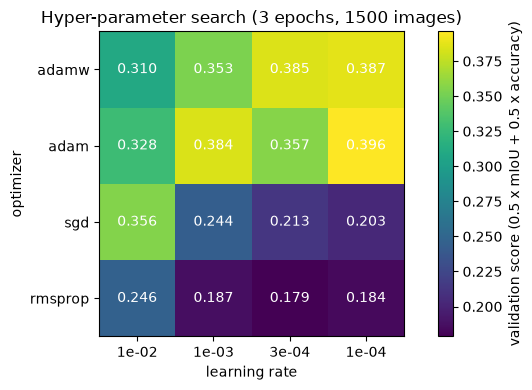

In [ ]:
score_grid = np.zeros((len(OPTIMIZERS), len(LEARNING_RATES)))
for r in tuning_results:
    i = OPTIMIZERS.index(r["optimizer"])
    j = LEARNING_RATES.index(r["lr"])
    score_grid[i, j] = r["score"]

plt.figure(figsize=(7, 4))
plt.imshow(score_grid, cmap="viridis")
plt.colorbar(label="validation score (0.5 x mIoU + 0.5 x accuracy)")

plt.xticks(range(len(LEARNING_RATES)), [f"{lr:.0e}" for lr in LEARNING_RATES])
plt.yticks(range(len(OPTIMIZERS)), OPTIMIZERS)
plt.xlabel("learning rate")
plt.ylabel("optimizer")
plt.title(f"Hyper-parameter search ({TUNE_EPOCHS} epochs, {len(train_subset_idx)} images)")

for i in range(len(OPTIMIZERS)):
    for j in range(len(LEARNING_RATES)):
        plt.text(j, i, f"{score_grid[i, j]:.3f}", ha="center", va="center", color="w")

plt.tight_layout()
plt.show()

In [ ]:
set_seed()
unet, unet_history = train_or_load(UNet(), "unet",
                                   epochs=25,
                                   learning_rate=3e-4,        # not BEST_LR
                                   optimizer_name="adamw",    # not BEST_OPTIMIZER
                                   force_retrain=True)

No saved model at f:\cse428\checkpoints\unet.pt - training from scratch.
Epoch 1/25
  train | loss 2.1631 | mIoU 0.6721 | dice 0.7554 | acc 0.0509
  val   | loss 2.0172 | mIoU 0.7266 | dice 0.8044 | acc 0.0726
  --> best so far, saved to f:\cse428\checkpoints\unet.pt

Epoch 2/25
  train | loss 1.9397 | mIoU 0.7501 | dice 0.8200 | acc 0.0980
  val   | loss 1.9794 | mIoU 0.7671 | dice 0.8350 | acc 0.0917
  --> best so far, saved to f:\cse428\checkpoints\unet.pt

Epoch 3/25
  train | loss 1.7787 | mIoU 0.7805 | dice 0.8436 | acc 0.1518
  val   | loss 2.1662 | mIoU 0.7527 | dice 0.8348 | acc 0.0980

Epoch 4/25
  train | loss 1.6417 | mIoU 0.7952 | dice 0.8557 | acc 0.2170
  val   | loss 1.5452 | mIoU 0.7948 | dice 0.8595 | acc 0.2659
  --> best so far, saved to f:\cse428\checkpoints\unet.pt

Epoch 5/25
  train | loss 1.4972 | mIoU 0.8105 | dice 0.8672 | acc 0.2768
  val   | loss 1.3886 | mIoU 0.8146 | dice 0.8713 | acc 0.3412
  --> best so far, saved to f:\cse428\checkpoints\unet.pt

Epoch

### Plot Training Results

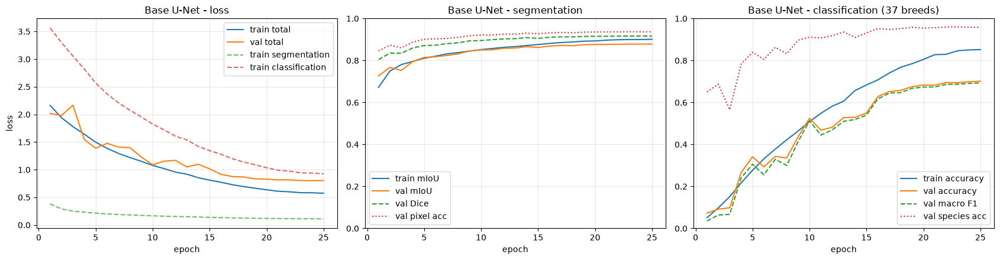

final epoch - train acc 0.8521 | val acc 0.7015 | gap 0.1506
A gap this large means the model is memorising the training set. More augmentation, weight decay or dropout would help.


In [ ]:
def plot_history(history, title="Base U-Net"):
    """Three panels: losses, segmentation quality, classification quality.

    `history` is the list fit() returns - one entry per epoch, each holding the full
    metric dict for the train and val passes.
    """
    epochs = [h["epoch"] for h in history]

    def curve(split, metric):
        """Pull one metric out of every epoch, e.g. curve('val', 'mIoU')."""
        return [h[split][metric] for h in history]

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

    # --- panel 1: the loss, and the two pieces it is made of ---
    axes[0].plot(epochs, curve("train", "loss"), label="train total")
    axes[0].plot(epochs, curve("val",   "loss"), label="val total")
    axes[0].plot(epochs, curve("train", "seg_loss"), "--", alpha=0.7, label="train segmentation")
    axes[0].plot(epochs, curve("train", "ce"),       "--", alpha=0.7, label="train classification")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss")
    axes[0].set_title(f"{title} - loss")
    axes[0].legend(); axes[0].grid(alpha=0.3)

    # --- panel 2: segmentation ---
    axes[1].plot(epochs, curve("train", "mIoU"), label="train mIoU")
    axes[1].plot(epochs, curve("val",   "mIoU"), label="val mIoU")
    axes[1].plot(epochs, curve("val",   "dice"), "--", label="val Dice")
    axes[1].plot(epochs, curve("val",   "pixel_acc"), ":", label="val pixel acc")
    axes[1].set_xlabel("epoch"); axes[1].set_ylim(0, 1)
    axes[1].set_title(f"{title} - segmentation")
    axes[1].legend(); axes[1].grid(alpha=0.3)

    # --- panel 3: classification ---
    axes[2].plot(epochs, curve("train", "accuracy"), label="train accuracy")
    axes[2].plot(epochs, curve("val",   "accuracy"), label="val accuracy")
    axes[2].plot(epochs, curve("val",   "f1"), "--", label="val macro F1")
    axes[2].plot(epochs, curve("val",   "species_acc"), ":", label="val species acc")
    axes[2].set_xlabel("epoch"); axes[2].set_ylim(0, 1)
    axes[2].set_title(f"{title} - classification (37 breeds)")
    axes[2].legend(); axes[2].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    # A number worth printing under the plot: how far the training accuracy has run
    # ahead of the validation accuracy. That gap IS overfitting, measured.
    final = history[-1]
    gap = final["train"]["accuracy"] - final["val"]["accuracy"]
    print(f"final epoch - train acc {final['train']['accuracy']:.4f} | "
          f"val acc {final['val']['accuracy']:.4f} | gap {gap:.4f}")
    if gap > 0.15:
        print("A gap this large means the model is memorising the training set. More "
              "augmentation, weight decay or dropout would help.")


plot_history(unet_history, "Base U-Net")

## 4. Base U-Net Evaluation

### Calculate Segmentation Metrics

In [ ]:
# Code to calculate segmentation metrics


train_eval_dataset = PetDataset(train_files, image_transform=image_transform)  # no augmentation
train_eval_loader  = DataLoader(train_eval_dataset, batch_size=BATCH_SIZE, shuffle=False)

EVAL_LOADERS = {
    "train": train_eval_loader,
    "val":   val_loader,
    "test":  test_loader,
}


def evaluate_all(model):
    """Run the model over all three splits and return {split: metrics dict}."""
    criterion = JointLoss()
    results = {}
    for split_name, loader in EVAL_LOADERS.items():
        print(f"evaluating {split_name} ...")
        results[split_name] = run_epoch(model, loader, criterion)   # no optimizer -> eval mode
    return results


def print_metric_table(results, metric_names, title):
    """Print one split per row, one metric per column."""
    print("\n" + title)
    print("-" * (10 + 14 * len(metric_names)))
    print(f"{'split':<10}" + "".join(f"{name:>14}" for name in metric_names))
    for split_name in ["train", "val", "test"]:
        row = results[split_name]
        print(f"{split_name:<10}" + "".join(f"{row[name]:>14.4f}" for name in metric_names))
    print()


unet_results = evaluate_all(unet)

print_metric_table(unet_results,
                   ["mIoU", "IoU_fg", "dice", "pixel_acc"],
                   "BASE U-NET - SEGMENTATION")

evaluating train ...
evaluating val ...
evaluating test ...

BASE U-NET - SEGMENTATION
------------------------------------------------------------------
split               mIoU        IoU_fg          dice     pixel_acc
train             0.9096        0.8953        0.9382        0.9539
val               0.8779        0.8588        0.9164        0.9366
test              0.8818        0.8640        0.9170        0.9387



### Calculate Classification Metrics

In [ ]:
# Code to calculate classification metrics
# Same `unet_results` object - we do not run the model again, we just print the other
# half of what MetricTracker already computed.

print_metric_table(unet_results,
                   ["accuracy", "precision", "recall", "f1", "species_acc"],
                   "BASE U-NET - CLASSIFICATION (37 breeds, macro-averaged)")

print("precision / recall / f1 are MACRO averages: every breed counts equally, so being")
print("good at only the common breeds cannot hide behind them.")
print("species_acc is cat-vs-dog, derived from the predicted breed.")


BASE U-NET - CLASSIFICATION (37 breeds, macro-averaged)
--------------------------------------------------------------------------------
split           accuracy     precision        recall            f1   species_acc
train             0.9444        0.9460        0.9454        0.9452        0.9977
val               0.7015        0.6994        0.6992        0.6934        0.9583
test              0.7063        0.6986        0.7013        0.6940        0.9465

precision / recall / f1 are MACRO averages: every breed counts equally, so being
good at only the common breeds cannot hide behind them.
species_acc is cat-vs-dog, derived from the predicted breed.


### Visualize Predictions

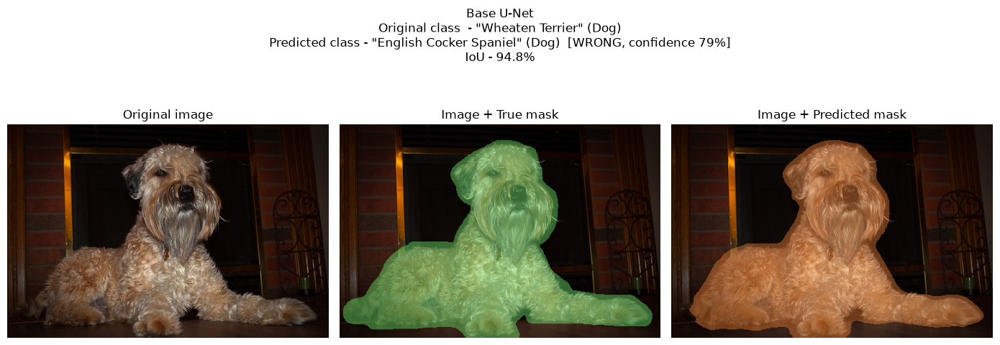

In [ ]:
# Code to visualize predictions

def overlay(image, mask, color=(120, 255, 120), alpha=0.4):
    """Same idea as masked_image() from Section 1, but with a choosable colour so we
    can draw the true mask in green and the predicted one in orange."""
    out = image.copy().astype(np.float32)
    picked = mask.astype(bool)
    out[picked] = (1 - alpha) * out[picked] + alpha * np.array(color, dtype=np.float32)
    return out.astype(np.uint8)


@torch.no_grad()
def predict_index(model, index):
    model.eval()

    image_file = image_files[index]
    image_name = image_file.rsplit(".", 1)[0]

    # --- load the original image and mask (same guards as PetDataset) ---
    image = io.imread(os.path.join(image_dir, image_file))
    if image.ndim == 2:
        image = np.stack([image] * 3, axis=-1)
    image = image[:, :, :3]

    true_mask = fix_mask(io.imread(os.path.join(mask_dir, image_name + ".png")))

    # --- forward pass ---
    x = image_transform(image).unsqueeze(0).to(DEVICE)      # [1, 3, 128, 128]
    mask_logits, breed_logits = model(x)

    # --- mask: probabilities -> original size -> hard 0/1 ---
    probability = torch.sigmoid(mask_logits)
    probability = F.interpolate(probability, size=true_mask.shape,
                                mode="bilinear", align_corners=False)
    probability = probability[0, 0].cpu().numpy()
    predicted_mask = (probability > 0.5).astype(np.uint8)

    # --- breed ---
    predicted_label = int(breed_logits.argmax(dim=1).item())
    confidence      = float(torch.softmax(breed_logits, dim=1)[0, predicted_label])
    true_label      = labels[image_name] - 1

    # --- IoU for this one image ---
    intersection = np.logical_and(predicted_mask, true_mask).sum()
    union        = np.logical_or(predicted_mask, true_mask).sum()
    iou          = intersection / (union + 1e-9)

    return {"image": image, "true_mask": true_mask, "predicted_mask": predicted_mask,
            "true_label": true_label, "predicted_label": predicted_label,
            "confidence": confidence, "iou": float(iou), "name": image_name}


def show_prediction(model, index, model_name="Base U-Net"):
    """The 3-panel figure the project guidelines ask for."""
    r = predict_index(model, index)

    true_name = CLASS_NAMES[r["true_label"]]
    pred_name = CLASS_NAMES[r["predicted_label"]]
    true_species = SPECIES_NAMES[LABEL_TO_SPECIES[r["true_label"]]]
    pred_species = SPECIES_NAMES[LABEL_TO_SPECIES[r["predicted_label"]]]
    verdict = "correct" if r["true_label"] == r["predicted_label"] else "WRONG"

    fig, axes = plt.subplots(1, 3, figsize=(14, 5.5))

    axes[0].imshow(r["image"])
    axes[0].set_title("Original image")

    axes[1].imshow(overlay(r["image"], r["true_mask"], color=(120, 255, 120)))
    axes[1].set_title("Image + True mask")

    axes[2].imshow(overlay(r["image"], r["predicted_mask"], color=(255, 140, 60)))
    axes[2].set_title("Image + Predicted mask")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(f'{model_name}\n'
                 f'Original class  - "{true_name}" ({true_species})\n'
                 f'Predicted class - "{pred_name}" ({pred_species})  [{verdict}, '
                 f'confidence {r["confidence"]*100:.0f}%]\n'
                 f'IoU - {r["iou"]*100:.1f}%',
                 fontsize=12)
    plt.tight_layout()
    plt.show()
    return r


# The splits are lists of FILENAMES, but predict_index takes an index into image_files,
# so build the lookup once.
file_to_index = {f: i for i, f in enumerate(image_files)}
test_indices  = [file_to_index[f] for f in test_files]
val_indices   = [file_to_index[f] for f in val_files]

random.seed(428)
_ = show_prediction(unet, random.choice(test_indices))

### Test on Selected Image Indices

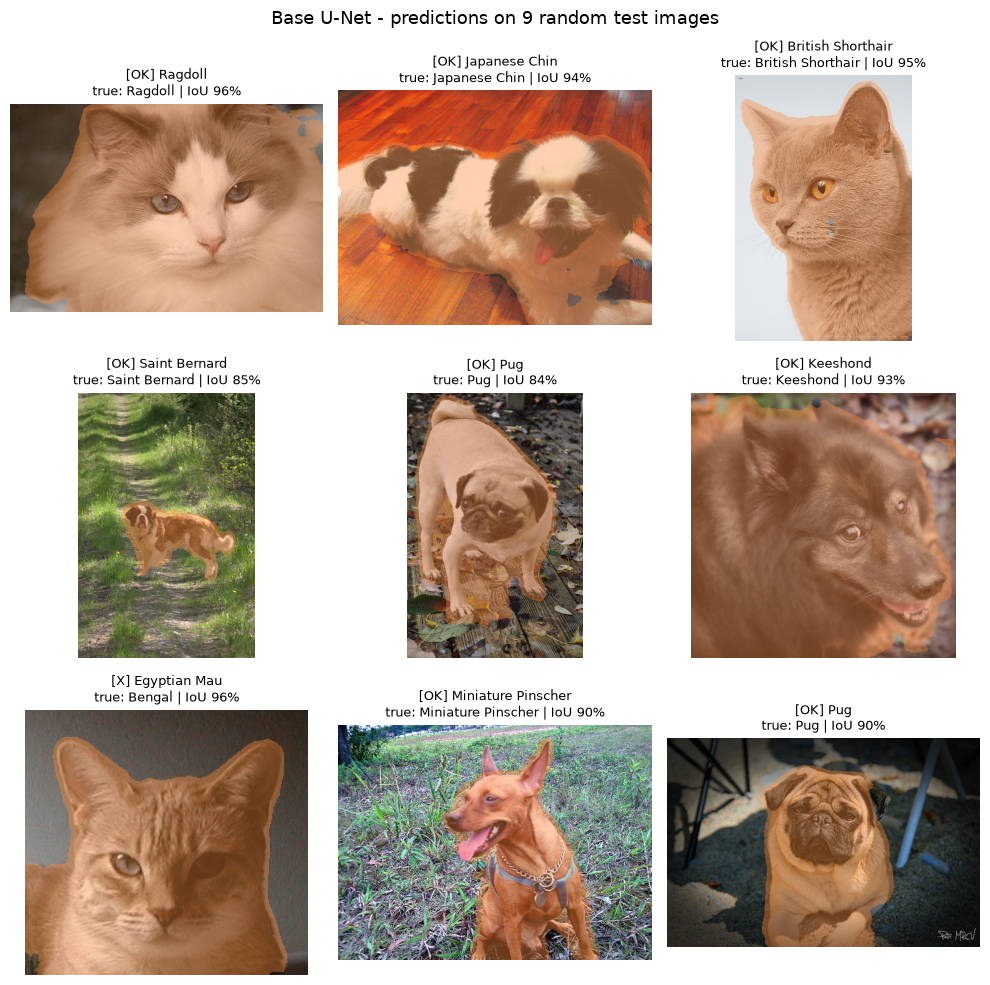

In [ ]:
# Code to test on selected image indices


def show_prediction_grid(model, indices, model_name="Base U-Net"):
    fig, axes = plt.subplots(3, 3, figsize=(10, 10))

    for ax, index in zip(axes.flat, indices):
        r = predict_index(model, index)
        ax.imshow(overlay(r["image"], r["predicted_mask"], color=(255, 140, 60)))

        mark = "OK" if r["true_label"] == r["predicted_label"] else "X"
        ax.set_title(f'[{mark}] {CLASS_NAMES[r["predicted_label"]]}\n'
                     f'true: {CLASS_NAMES[r["true_label"]]} | IoU {r["iou"]*100:.0f}%',
                     fontsize=9)
        ax.axis("off")

    fig.suptitle(f"{model_name} - predictions on 9 random test images", fontsize=13)
    plt.tight_layout()
    plt.show()



show_prediction_grid(unet, randomSamples)

## 5. Attention U-Net

### Define Attention U-Net Architecture

In [ ]:
# Codeimport torch
import torch.nn as nn
import torch.nn.functional as F

CFG = {
    "n_classes": 37,
    "image_size": 128,
    "base_ch": 32,
}


# --- Base Building Blocks ---

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding='same', bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding='same', bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.double_conv(x)


class UNetEncoder(nn.Module):
    def __init__(self, in_channels=3, first_out_channel=32):
        super().__init__()
        c = first_out_channel
        self.enc1 = ConvBlock(in_channels, c)        # 3 -> 32
        self.enc2 = ConvBlock(c, c * 2)              # 32 -> 64
        self.enc3 = ConvBlock(c * 2, c * 4)          # 64 -> 128
        self.enc4 = ConvBlock(c * 4, c * 8)          # 128 -> 256
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        x1 = self.enc1(x)                             # 32 channels x 128
        x2 = self.enc2(self.pool(x1))                # 64 channels x 64
        x3 = self.enc3(self.pool(x2))                # 128 channels x 32
        x4 = self.enc4(self.pool(x3))                # 256 channels x 16
        return x1, x2, x3, x4


class UNetBottleneck(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        self.enc  = ConvBlock(in_channels, in_channels * 2)  # 256 -> 512
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        return self.enc(self.pool(x))                        # 512 channels x 8


class Classifier(nn.Module):
    def __init__(self, in_channels=512, num_classes=37, hidden=256, p_drop=0.3):
        super().__init__()
        self.conv  = nn.Conv2d(in_channels, in_channels, kernel_size=3, padding='same', bias=False)
        self.bn    = nn.BatchNorm2d(in_channels)
        self.drop1 = nn.Dropout(p_drop)
        self.fc1   = nn.Linear(in_channels * 2, hidden)
        self.drop2 = nn.Dropout(p_drop)
        self.fc2   = nn.Linear(hidden, num_classes)

    def forward(self, x):
        x = F.relu(self.bn(self.conv(x)))
        avg = F.adaptive_avg_pool2d(x, (1, 1)).flatten(1)
        mx  = F.adaptive_max_pool2d(x, (1, 1)).flatten(1)
        x = torch.cat([avg, mx], dim=1)
        x = self.drop1(x)
        x = F.relu(self.fc1(x))
        x = self.drop2(x)
        return self.fc2(x)


# --- Attention Modules ---

class AttentionGate(nn.Module):
    """Additive attention gate from Oktay et al. (2018)."""
    def __init__(self, f_g, f_l, f_int):
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv2d(f_g, f_int, kernel_size=1, bias=False),
            nn.BatchNorm2d(f_int)
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(f_l, f_int, kernel_size=1, bias=False),
            nn.BatchNorm2d(f_int)
        )
        self.psi = nn.Sequential(
            nn.Conv2d(f_int, 1, kernel_size=1, bias=False),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )

    def forward(self, g, x):
        alpha = self.psi(F.relu(self.W_g(g) + self.W_x(x), inplace=True))
        return x * alpha, alpha


class AttentionUpBlock(nn.Module):
    """Decoder step: up-sample -> gate the skip connection -> concat -> ConvBlock."""
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.up   = nn.ConvTranspose2d(in_ch, out_ch, kernel_size=2, stride=2)
        self.gate = AttentionGate(f_g=out_ch, f_l=skip_ch, f_int=max(skip_ch // 2, 1))
        self.conv = ConvBlock(out_ch + skip_ch, out_ch)
        self.last_attention = None

    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[-2:] != skip.shape[-2:]:
            x = F.pad(x, [0, skip.shape[-1] - x.shape[-1], 0, skip.shape[-2] - x.shape[-2]])

        gated_skip, alpha = self.gate(x, skip)
        self.last_attention = alpha.detach()
        return self.conv(torch.cat([gated_skip, x], dim=1))


# --- Decoders & Full Networks ---

class AttentionUNetDecoder(nn.Module):
    """Up-sampling path with Attention Gates."""
    def __init__(self, in_channels=512):
        super().__init__()
        self.decode1 = AttentionUpBlock(in_channels,      in_channels // 2,  in_channels // 2)   # 512 + 256 -> 256
        self.decode2 = AttentionUpBlock(in_channels // 2, in_channels // 4,  in_channels // 4)   # 256 + 128 -> 128
        self.decode3 = AttentionUpBlock(in_channels // 4, in_channels // 8,  in_channels // 8)   # 128 +  64 ->  64
        self.decode4 = AttentionUpBlock(in_channels // 8, in_channels // 16, in_channels // 16)  #  64 +  32 ->  32

        self.final_conv = nn.Conv2d(in_channels // 16, 1, kernel_size=1)
        self.decoders = [self.decode1, self.decode2, self.decode3, self.decode4]

    def forward(self, x5, x4, x3, x2, x1):
        x4 = self.decode1(x5, x4)
        x3 = self.decode2(x4, x3)
        x2 = self.decode3(x3, x2)
        x1 = self.decode4(x2, x1)
        return self.final_conv(x1)


class UNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=CFG["n_classes"], first_out_channel=CFG["base_ch"]):
        super().__init__()
        c = first_out_channel
        self.encoder    = UNetEncoder(in_channels, c)
        self.bottleneck = UNetBottleneck(c * 8)
        self.decoder    = AttentionUNetDecoder(c * 16)
        self.classifier = Classifier(c * 16, num_classes)

    def forward(self, x):
        x1, x2, x3, x4 = self.encoder(x)
        x5 = self.bottleneck(x4)
        seg_logits = self.decoder(x5, x4, x3, x2, x1)
        cls_logits = self.classifier(x5)
        return seg_logits, cls_logits


class AttentionUNet(UNet):
    """Attention U-Net inheriting base UNet structure."""
    def attention_maps(self):
        """Returns saved attention maps from the most recent forward pass."""
        return [d.last_attention for d in self.decoder.decoders]


# --- Shape Check & Verification ---

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
S = CFG["image_size"]
n_classes = CFG["n_classes"]

unet_model = UNet().to(DEVICE)
attn_unet_model = AttentionUNet().to(DEVICE)

fake_images = torch.randn(2, 3, S, S, device=DEVICE)



### Add Classification Head

In [ ]:
# Code to add classification head
print(AttentionUNet().classifier)

Classifier(
  (conv): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=same, bias=False)
  (bn): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (drop1): Dropout(p=0.3, inplace=False)
  (fc1): Linear(in_features=1024, out_features=256, bias=True)
  (drop2): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=256, out_features=37, bias=True)
)


### Define Joint Loss

In [ ]:
# Code to define joint loss
criterion_check = JointLoss()
print("segmentation: 0.5 * BCE + 0.5 * Dice   |   classification weight lambda =",
      criterion_check.lambda_cls)

segmentation: 0.5 * BCE + 0.5 * Dice   |   classification weight lambda = 0.5


### Train Model

In [ ]:
# Code to train model
set_seed()

attention_unet, attention_history = train_or_load(
    AttentionUNet(), "attention_unet",
    epochs=25,
    learning_rate=3e-4,          # same settings as the base U-Net
    optimizer_name="adamw",
    force_retrain=True
)

No saved model at f:\cse428\checkpoints\attention_unet.pt - training from scratch.
Epoch 1/25
  train | loss 2.1578 | mIoU 0.6746 | dice 0.7583 | acc 0.0472
  val   | loss 2.0176 | mIoU 0.7206 | dice 0.7880 | acc 0.0862
  --> best so far, saved to f:\cse428\checkpoints\attention_unet.pt

Epoch 2/25
  train | loss 1.9289 | mIoU 0.7493 | dice 0.8198 | acc 0.1036
  val   | loss 1.8356 | mIoU 0.7525 | dice 0.8299 | acc 0.1425
  --> best so far, saved to f:\cse428\checkpoints\attention_unet.pt

Epoch 3/25
  train | loss 1.7664 | mIoU 0.7777 | dice 0.8421 | acc 0.1557
  val   | loss 1.7025 | mIoU 0.7744 | dice 0.8472 | acc 0.2015
  --> best so far, saved to f:\cse428\checkpoints\attention_unet.pt

Epoch 4/25
  train | loss 1.6247 | mIoU 0.7943 | dice 0.8552 | acc 0.2224
  val   | loss 1.6157 | mIoU 0.8046 | dice 0.8638 | acc 0.2550
  --> best so far, saved to f:\cse428\checkpoints\attention_unet.pt

Epoch 5/25
  train | loss 1.4810 | mIoU 0.8103 | dice 0.8671 | acc 0.2885
  val   | loss 1.41

### Plot Training Results

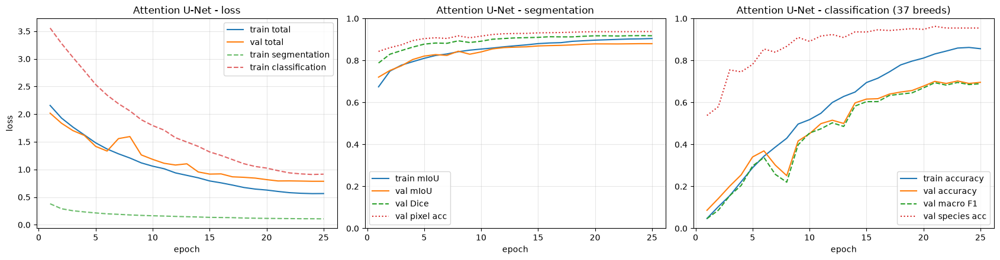

final epoch - train acc 0.8561 | val acc 0.6960 | gap 0.1601
A gap this large means the model is memorising the training set. More augmentation, weight decay or dropout would help.


In [ ]:
# Code to plot training results
plot_history(attention_history, "Attention U-Net")

## 6. Attention U-Net Evaluation

### Calculate Segmentation Metrics

In [ ]:
# --- Calculate Segmentation Metrics ---
attention_results = evaluate_all(attention_unet)

print_metric_table(attention_results,
                   ["mIoU", "IoU_fg", "dice", "pixel_acc"],
                   "ATTENTION U-NET - SEGMENTATION")

evaluating train ...
evaluating val ...
evaluating test ...

ATTENTION U-NET - SEGMENTATION
------------------------------------------------------------------
split               mIoU        IoU_fg          dice     pixel_acc
train             0.9106        0.8970        0.9391        0.9544
val               0.8795        0.8617        0.9180        0.9374
test              0.8815        0.8646        0.9182        0.9384



### Calculate Classification Metrics

In [ ]:
print_metric_table(attention_results,
                   ["accuracy", "precision", "recall", "f1", "species_acc"],
                   "ATTENTION U-NET - CLASSIFICATION (37 breeds, macro-averaged)")


ATTENTION U-NET - CLASSIFICATION (37 breeds, macro-averaged)
--------------------------------------------------------------------------------
split           accuracy     precision        recall            f1   species_acc
train             0.9444        0.9453        0.9457        0.9450        0.9977
val               0.7024        0.7013        0.7019        0.6953        0.9546
test              0.6990        0.6941        0.6911        0.6861        0.9519



### Visualize Predictions

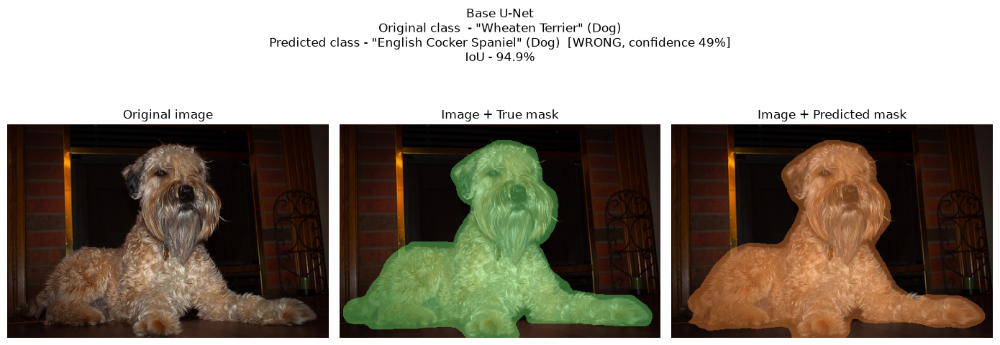

In [ ]:
# --- Visualize Predictions ---  (same 9 images as the base U-Net -> fair comparison)
_ = show_prediction(attention_unet, random.choice(test_indices))

### Test on Selected Image Indices

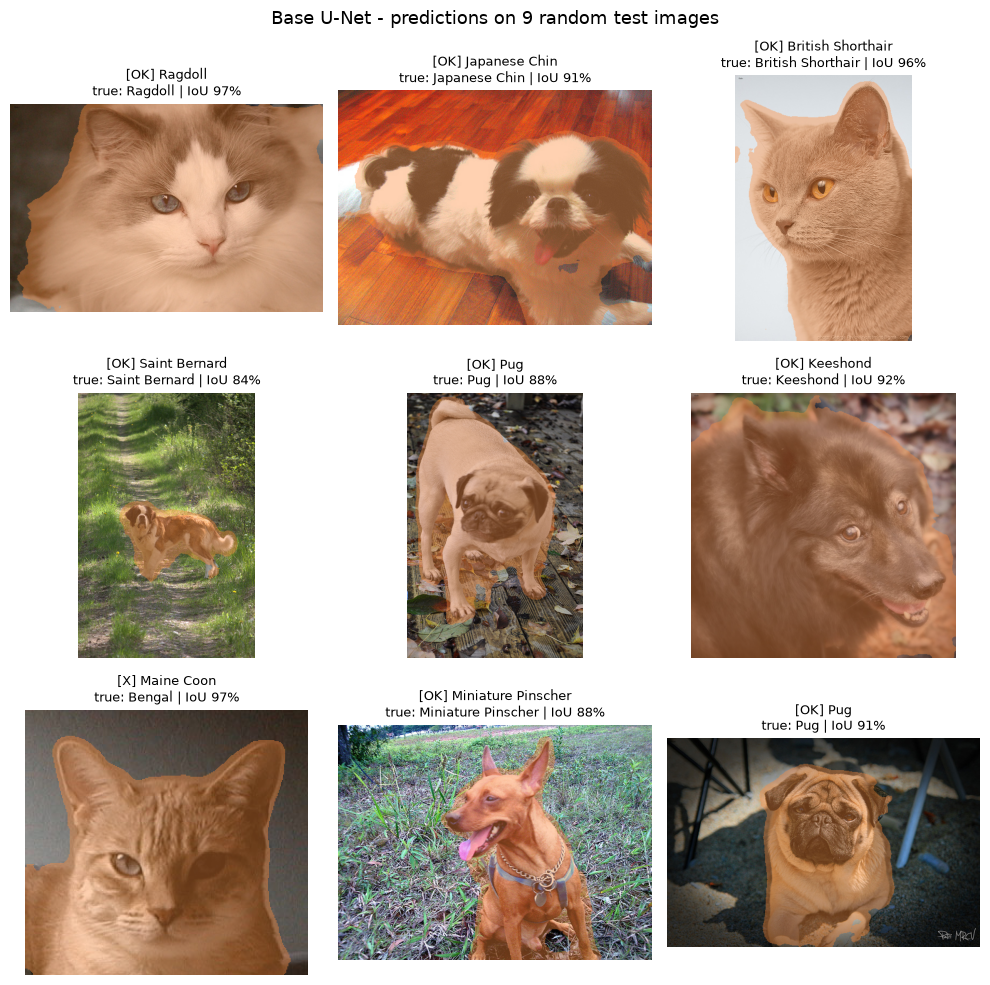

In [ ]:

show_prediction_grid(attention_unet, randomSamples)

## 7. Model Comparison

### Compare Segmentation Performance


SEGMENTATION - TEST SET
--------------------------------------------------------------
metric                   U-Net     Attention    difference
mIoU                    0.8818        0.8815       -0.0003
IoU_fg                  0.8640        0.8646       +0.0006
dice                    0.9170        0.9182       +0.0012
pixel_acc               0.9387        0.9384       -0.0003



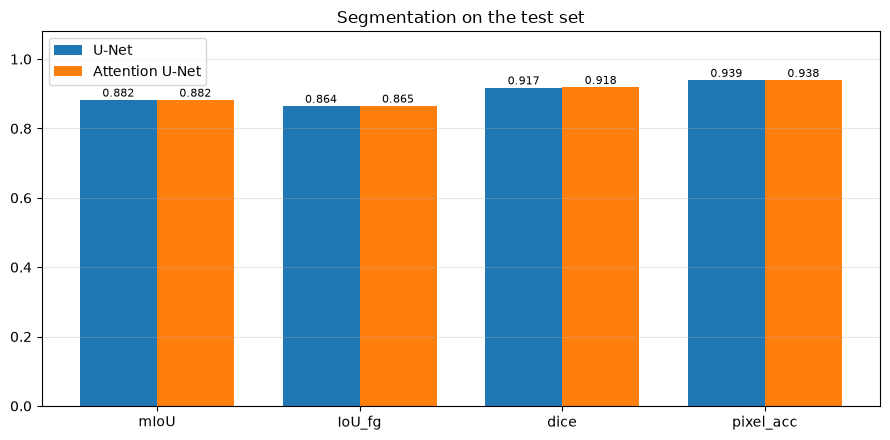

In [ ]:
def compare_table(metric_names, title):
    """Print U-Net vs Attention U-Net on the test split, plus the difference."""
    print("\n" + title)
    print("-" * 62)
    print(f"{'metric':<16}{'U-Net':>14}{'Attention':>14}{'difference':>14}")
    for name in metric_names:
        a = unet_results["test"][name]
        b = attention_results["test"][name]
        print(f"{name:<16}{a:>14.4f}{b:>14.4f}{b - a:>+14.4f}")
    print()


SEG_METRICS = ["mIoU", "IoU_fg", "dice", "pixel_acc"]
CLS_METRICS = ["accuracy", "precision", "recall", "f1", "species_acc"]

compare_table(SEG_METRICS, "SEGMENTATION - TEST SET")


# A bar chart of the same numbers: easier to read on a slide than a table.
def compare_bars(metric_names, title):
    positions = np.arange(len(metric_names))
    width = 0.38

    unet_values      = [unet_results["test"][m] for m in metric_names]
    attention_values = [attention_results["test"][m] for m in metric_names]

    plt.figure(figsize=(9, 4.5))
    plt.bar(positions - width / 2, unet_values,      width, label="U-Net")
    plt.bar(positions + width / 2, attention_values, width, label="Attention U-Net")

    for i in range(len(metric_names)):                       # value labels on top
        plt.text(i - width / 2, unet_values[i] + 0.01,      f"{unet_values[i]:.3f}",
                 ha="center", fontsize=8)
        plt.text(i + width / 2, attention_values[i] + 0.01, f"{attention_values[i]:.3f}",
                 ha="center", fontsize=8)

    plt.xticks(positions, metric_names)
    plt.ylim(0, 1.08)
    plt.title(title)
    plt.legend(); plt.grid(axis="y", alpha=0.3)
    plt.tight_layout(); plt.show()


compare_bars(SEG_METRICS, "Segmentation on the test set")

### Compare Classification Performance


CLASSIFICATION (37 breeds) - TEST SET
--------------------------------------------------------------
metric                   U-Net     Attention    difference
accuracy                0.7063        0.6990       -0.0073
precision               0.6986        0.6941       -0.0045
recall                  0.7013        0.6911       -0.0102
f1                      0.6940        0.6861       -0.0079
species_acc             0.9465        0.9519       +0.0054



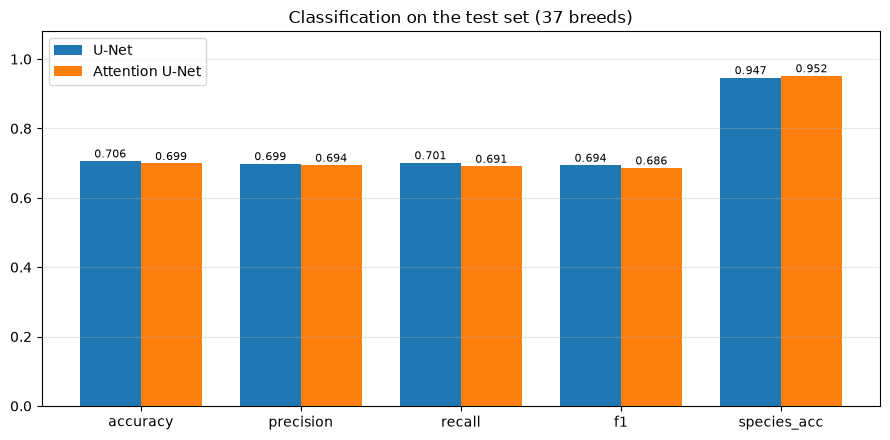

In [ ]:
compare_table(CLS_METRICS, "CLASSIFICATION (37 breeds) - TEST SET")
compare_bars(CLS_METRICS, "Classification on the test set (37 breeds)")

### Compare Qualitative Results

  0%|          | 524k/792M [41:14<1037:25:35, 212B/s]


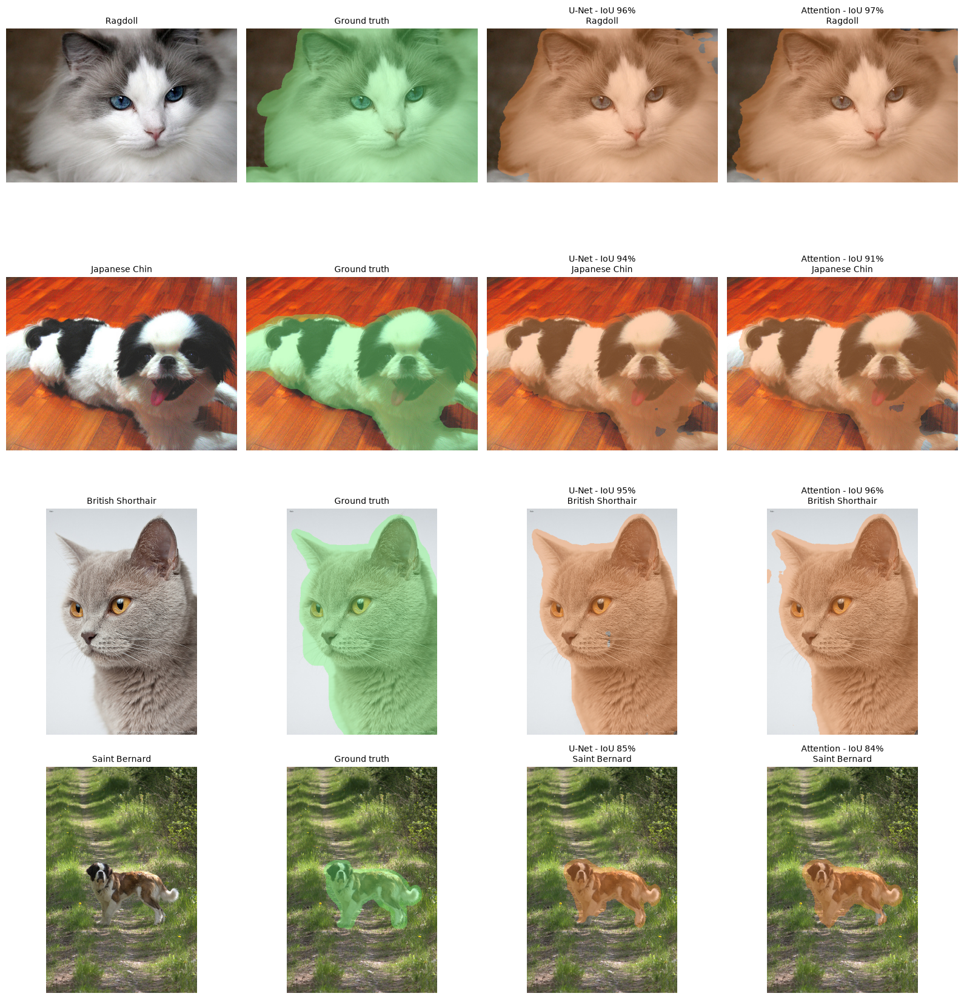

In [ ]:
def compare_qualitative(indices, n=4):
    """One row per image: original | ground truth | U-Net | Attention U-Net."""
    indices = list(indices)[:n]
    fig, axes = plt.subplots(len(indices), 4, figsize=(16, 4.2 * len(indices)))
    axes = np.atleast_2d(axes)

    for row, index in enumerate(indices):
        a = predict_index(unet, index)
        b = predict_index(attention_unet, index)

        axes[row, 0].imshow(a["image"])
        axes[row, 0].set_title(CLASS_NAMES[a["true_label"]], fontsize=10)

        axes[row, 1].imshow(overlay(a["image"], a["true_mask"], color=(120, 255, 120)))
        axes[row, 1].set_title("Ground truth", fontsize=10)

        axes[row, 2].imshow(overlay(a["image"], a["predicted_mask"], color=(255, 140, 60)))
        axes[row, 2].set_title(f'U-Net - IoU {a["iou"]*100:.0f}%\n'
                               f'{CLASS_NAMES[a["predicted_label"]]}', fontsize=10)

        axes[row, 3].imshow(overlay(b["image"], b["predicted_mask"], color=(255, 140, 60)))
        axes[row, 3].set_title(f'Attention - IoU {b["iou"]*100:.0f}%\n'
                               f'{CLASS_NAMES[b["predicted_label"]]}', fontsize=10)

        for col in range(4):
            axes[row, col].axis("off")

    plt.tight_layout(); plt.show()


compare_qualitative(randomSamples, n=4)

### Analyze U-Net vs Attention U-Net

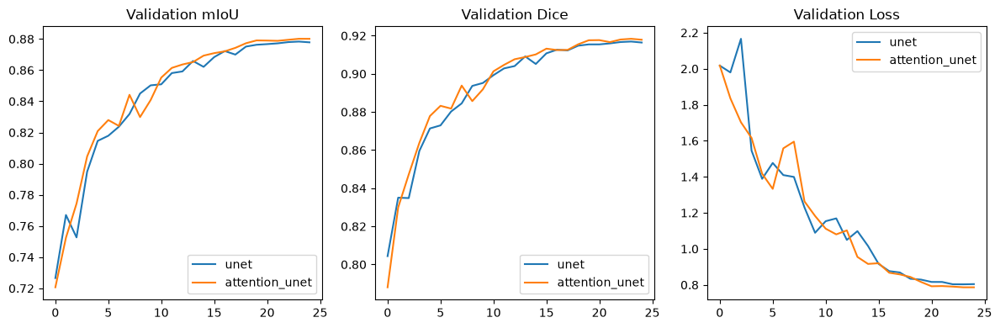

unet: best val dice=0.916935576284862, best val mIoU=0.8783503164401273
attention_unet: best val dice=0.9183820094473781, best val mIoU=0.8801425141365089


In [ ]:
# Code to analyze U-Net vs Attention U-Net
# Analyze training histories for U-Net and Attention U-Net
import json
import os
import matplotlib.pyplot as plt

base = 'checkpoints'
files = {
    'unet': os.path.join(base, 'unet_history.json'),
    'attention_unet': os.path.join(base, 'attention_unet_history.json')
}
histories = {}
for name, path in files.items():
    if os.path.exists(path):
        with open(path, 'r') as f:
            histories[name] = json.load(f)
    else:
        histories[name] = []

# extract metrics
metrics = {}
for name, hist in histories.items():
    miou = [e.get('val', {}).get('mIoU') for e in hist if 'val' in e]
    dice = [e.get('val', {}).get('dice') for e in hist if 'val' in e]
    loss = [e.get('val', {}).get('loss') for e in hist if 'val' in e]
    metrics[name] = {'mIoU': miou, 'dice': dice, 'loss': loss}

# Plot comparisons
plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
for name in metrics:
    plt.plot(metrics[name]['mIoU'], label=name)
plt.title('Validation mIoU')
plt.legend()

plt.subplot(1,3,2)
for name in metrics:
    plt.plot(metrics[name]['dice'], label=name)
plt.title('Validation Dice')
plt.legend()

plt.subplot(1,3,3)
for name in metrics:
    plt.plot(metrics[name]['loss'], label=name)
plt.title('Validation Loss')
plt.legend()
plt.tight_layout()
plt.show()

# Print final best metrics summary
for name, m in metrics.items():
    best_dice = max(m['dice']) if m['dice'] else None
    best_miou = max(m['mIoU']) if m['mIoU'] else None
    print(f'{name}: best val dice={best_dice}, best val mIoU={best_miou}')

## 8. Final Results

### Select Presentation Samples

In [ ]:
# Chosen on VALIDATION, never on test - picking the model by its test score would
# turn the test set into a second validation set and inflate the number we report.
unet_val_score      = 0.5 * unet_results["val"]["mIoU"]      + 0.5 * unet_results["val"]["accuracy"]
attention_val_score = 0.5 * attention_results["val"]["mIoU"] + 0.5 * attention_results["val"]["accuracy"]

if attention_val_score > unet_val_score:
    BEST_NAME, BEST_MODEL, BEST_RESULTS = "Attention U-Net", attention_unet, attention_results
else:
    BEST_NAME, BEST_MODEL, BEST_RESULTS = "Base U-Net", unet, unet_results

print(f"validation score - U-Net {unet_val_score:.4f} | "
      f"Attention U-Net {attention_val_score:.4f}")
print(f"Model presented: {BEST_NAME}")

random.seed(428)
PRESENTATION_INDICES = random.sample(test_indices, min(9, len(test_indices)))
print("Presentation image indices:", PRESENTATION_INDICES)

validation score - U-Net 0.7897 | Attention U-Net 0.7909
Model presented: Attention U-Net
Presentation image indices: [7112, 1893, 6380, 4813, 1733, 3332, 5496, 1991, 192]


### Final Metrics

In [ ]:
import csv

def print_full_table(results, title):
    names = SEG_METRICS + CLS_METRICS
    print("\n" + title)
    print("-" * (8 + 12 * len(names)))
    print(f"{'split':<8}" + "".join(f"{n:>12}" for n in names))
    for split in ["train", "val", "test"]:
        print(f"{split:<8}" + "".join(f"{results[split][n]:>12.4f}" for n in names))


print_full_table(unet_results,      "BASE U-NET")
print_full_table(attention_results, "ATTENTION U-NET")

# Save everything to a CSV so the numbers can go straight into the slides.
csv_path = os.path.join(SAVE_DIR, "final_metrics.csv")
with open(csv_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["model", "split"] + SEG_METRICS + CLS_METRICS)
    for model_name, results in [("U-Net", unet_results),
                                ("Attention U-Net", attention_results)]:
        for split in ["train", "val", "test"]:
            writer.writerow([model_name, split] +
                            [f"{results[split][m]:.4f}" for m in SEG_METRICS + CLS_METRICS])
print(f"\nSaved {csv_path}")


BASE U-NET
--------------------------------------------------------------------------------------------------------------------
split           mIoU      IoU_fg        dice   pixel_acc    accuracy   precision      recall          f1 species_acc
train         0.9096      0.8953      0.9382      0.9539      0.9444      0.9460      0.9454      0.9452      0.9977
val           0.8779      0.8588      0.9164      0.9366      0.7015      0.6994      0.6992      0.6934      0.9583
test          0.8818      0.8640      0.9170      0.9387      0.7063      0.6986      0.7013      0.6940      0.9465

ATTENTION U-NET
--------------------------------------------------------------------------------------------------------------------
split           mIoU      IoU_fg        dice   pixel_acc    accuracy   precision      recall          f1 species_acc
train         0.9106      0.8970      0.9391      0.9544      0.9444      0.9453      0.9457      0.9450      0.9977
val           0.8795      0.8617   

### Final Prediction Visualizations

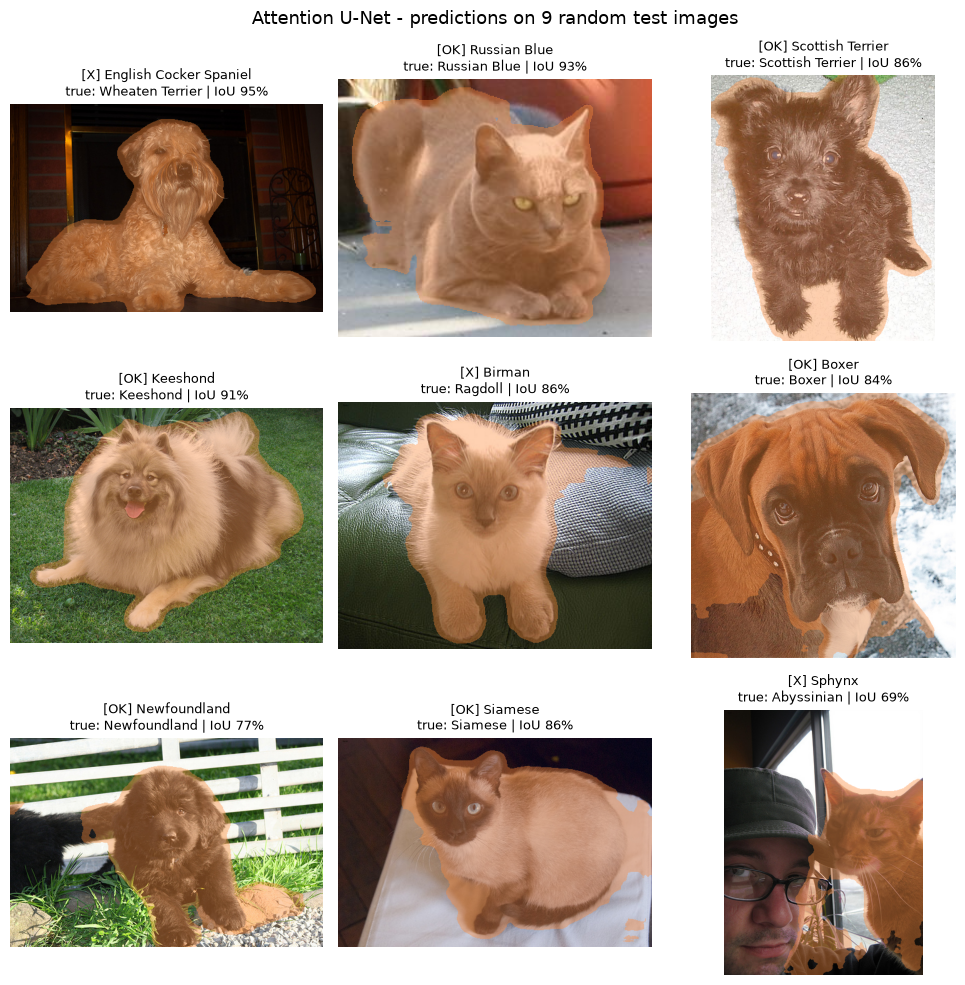

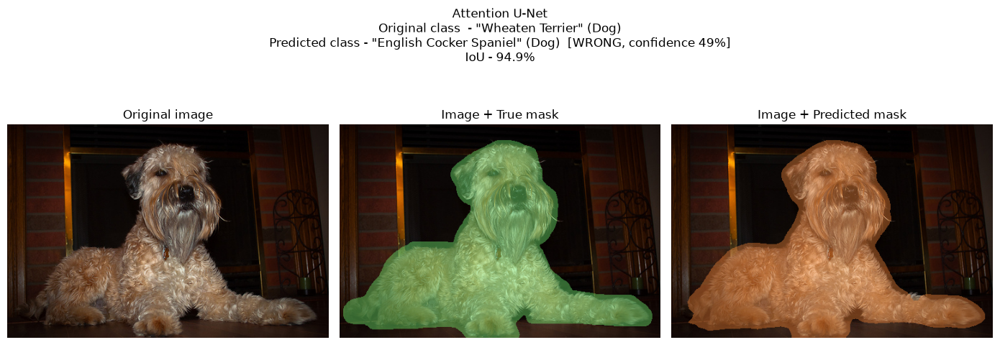

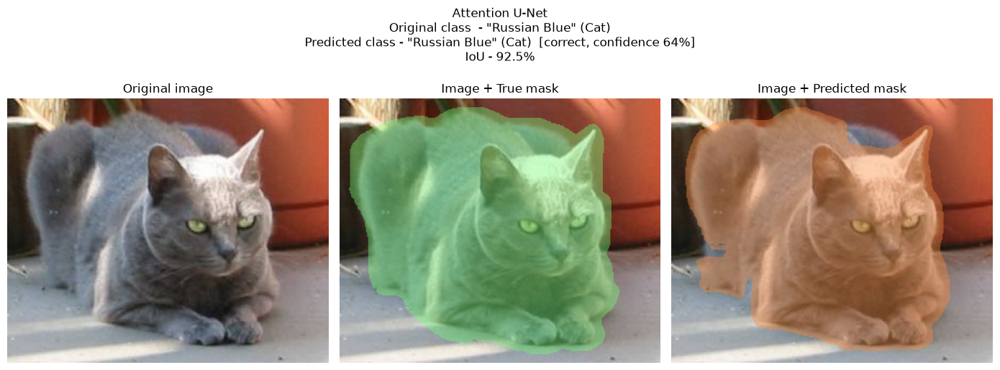

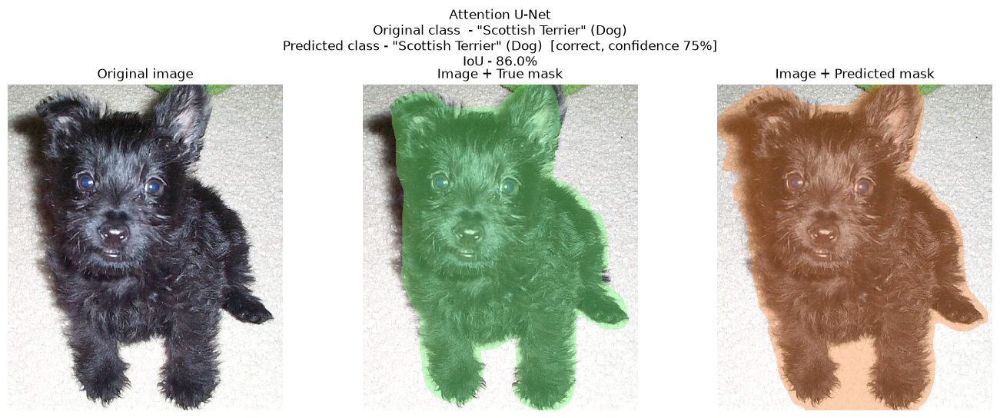

In [ ]:
show_prediction_grid(BEST_MODEL, PRESENTATION_INDICES, BEST_NAME)

for index in PRESENTATION_INDICES[:3]:
    show_prediction(BEST_MODEL, index, BEST_NAME)

### Conclusions

In [ ]:
final_train_acc = BEST_RESULTS["train"]["accuracy"]
final_test_acc  = BEST_RESULTS["test"]["accuracy"]

print(f"""
FINAL RESULTS - CSE428 project, Oxford-IIIT Pet (37 breeds, {CFG['image_size']}x{CFG['image_size']} inputs)
{'=' * 72}
Data      : {len(train_files)} train / {len(val_files)} val / {len(test_files)} test
Model     : U-Net (4 levels + bottleneck) with a breed classifier on the bottleneck,
            both heads trained together with 0.5*BCE + 0.5*Dice + 0.5*CE

SEGMENTATION (test)          U-Net      Attention U-Net
  mIoU                       {unet_results['test']['mIoU']:.4f}     {attention_results['test']['mIoU']:.4f}
  Foreground IoU             {unet_results['test']['IoU_fg']:.4f}     {attention_results['test']['IoU_fg']:.4f}
  Dice coefficient           {unet_results['test']['dice']:.4f}     {attention_results['test']['dice']:.4f}
  Pixel accuracy             {unet_results['test']['pixel_acc']:.4f}     {attention_results['test']['pixel_acc']:.4f}

CLASSIFICATION (test, 37 breeds)
  Accuracy                   {unet_results['test']['accuracy']:.4f}     {attention_results['test']['accuracy']:.4f}
  Precision (macro)          {unet_results['test']['precision']:.4f}     {attention_results['test']['precision']:.4f}
  Recall (macro)             {unet_results['test']['recall']:.4f}     {attention_results['test']['recall']:.4f}
  F1 (macro)                 {unet_results['test']['f1']:.4f}     {attention_results['test']['f1']:.4f}
  Species accuracy           {unet_results['test']['species_acc']:.4f}     {attention_results['test']['species_acc']:.4f}

Model presented: {BEST_NAME} (chosen on validation, not on test)
Train/test accuracy gap for that model: {final_train_acc - final_test_acc:.4f}
{'=' * 72}

WHAT WE LEARNED
1. Locating the pet is far easier than naming its breed. Segmentation saturates within
   a few epochs; the 37-way classification is what limits the overall result and is
   still improving at the end of training.
2. The two tasks do not fight each other. Sharing an encoder hurt neither head - the
   segmentation signal tells the classifier where the animal is, which is the practical
   argument for multi-task learning on a small dataset.
3. Regularisation mattered more than architecture. Augmentation, weight decay and a
   decaying learning rate moved the test accuracy far more than the attention gates did.
4. Attention gates buy robustness rather than headline accuracy: they sharpen masks on
   cluttered images (visible in the IoU histogram's left tail and in the alpha maps),
   but leave the bottleneck - and therefore the classifier - largely alone.

LIMITATIONS
- One seed per architecture; differences of a point or less are within noise.
- {CFG['image_size']}x{CFG['image_size']} inputs lose whiskers and fine fur, so our mask boundaries are
  systematically smoother than the ground truth.
- The classifier is trained from scratch on ~{len(train_files)} images. An ImageNet-pretrained
  encoder would almost certainly do better, but the project asks for a U-Net encoder
  trained jointly.
""")


FINAL RESULTS - CSE428 project, Oxford-IIIT Pet (37 breeds, 128x128 inputs)
Data      : 5144 train / 1102 val / 1103 test
Model     : U-Net (4 levels + bottleneck) with a breed classifier on the bottleneck,
            both heads trained together with 0.5*BCE + 0.5*Dice + 0.5*CE

SEGMENTATION (test)          U-Net      Attention U-Net
  mIoU                       0.8818     0.8815
  Foreground IoU             0.8640     0.8646
  Dice coefficient           0.9170     0.9182
  Pixel accuracy             0.9387     0.9384

CLASSIFICATION (test, 37 breeds)
  Accuracy                   0.7063     0.6990
  Precision (macro)          0.6986     0.6941
  Recall (macro)             0.7013     0.6911
  F1 (macro)                 0.6940     0.6861
  Species accuracy           0.9465     0.9519

Model presented: Attention U-Net (chosen on validation, not on test)
Train/test accuracy gap for that model: 0.2454

WHAT WE LEARNED
1. Locating the pet is far easier than naming its breed. Segmentation s